# Ebene 2: Wie stabil ist der KVV-Fahrplan?

Autor: Rustam T.

Was ändert sich von einem veröffentlichten Stand zum nächsten, und wie kurzfristig? Das Notebook rechnet nichts selbst. Es liest die Sichten aus `sql/09_kennzahlen.sql`, die `laden/lade_aenderungen.py` befüllt. Wie eine Änderung erkannt wird, steht in `analyse/diff.py` und in den Entscheidungen E15 bis E17.

**Vorläufig.** Das Archiv umfasst bisher fünf Stände (03. bis 07.11.2026), also vier Standpaare. Belastbare Aussagen zu Linien und Wochentagen gibt es frühestens nach drei Wochen.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from dotenv import load_dotenv

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "laden"))
from lade_postgres import verbinde

load_dotenv(REPO / ".env")
conn = verbinde()

def sql(abfrage: str) -> pd.DataFrame:
    cur = conn.execute(abfrage)
    return pd.DataFrame(cur.fetchall(), columns=[d.name for d in cur.description])

GRAFIKEN = REPO / "docs" / "grafiken"

# Fünf Änderungsarten in fester Reihenfolge (validiert: CVD-Abstand >= 9 zwischen Nachbarn).
# Drei Farben liegen unter 3:1 Kontrast, deshalb stehen Zahlen immer zusätzlich in Tabellen.
ARTEN = ["neu", "entfallen", "halteverlauf", "zeit", "betriebstage"]
FARBE = dict(zip(ARTEN, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]))
TEXT, TEXT2, RASTER, FLAECHE = "#0b0b0b", "#52514e", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": TEXT2, "xtick.color": TEXT2, "ytick.color": TEXT2,
    "axes.grid": True, "grid.color": RASTER, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "figure.facecolor": FLAECHE, "axes.facecolor": FLAECHE,
})

## Die Standpaare

Verglichen werden immer nur zwei direkt aufeinanderfolgende Stände. `geaendert` zählt Fahrten im Fenster, die im neuen Stand nicht mehr so fahren wie vorher (entfallen, anderer Halteverlauf, andere Zeit, ein Betriebstag fällt weg). Neue Fahrten zählen nicht als geändert, sonst hätte eine Linie, die mehr Fahrten bekommt, eine schlechtere Stabilität.

In [2]:
paare = sql("""SELECT standpaar_sk, stand_alt, stand_neu, abruf_neu, stunden_dazwischen, fehler_dazwischen,
                        fahrten_alt, geaendert, anteil_geaendert, ist_grosser_wechsel,
                        trip_id_nur_alt, trip_id_nur_neu
                   FROM v_standpaar ORDER BY abruf_neu""")
paare["paar"] = (pd.to_datetime(paare["stand_alt"].str[:10]).dt.strftime("%d.%m.") + " → "
                 + pd.to_datetime(paare["stand_neu"].str[:10]).dt.strftime("%d.%m."))
paare["anteil_prozent"] = (paare["anteil_geaendert"].astype(float) * 100).round(2)
paare[["paar", "stunden_dazwischen", "fahrten_alt", "geaendert", "anteil_prozent", "ist_grosser_wechsel"]]

,paar,stunden_dazwischen,fahrten_alt,geaendert,anteil_prozent,ist_grosser_wechsel
0,03.11. → 04.11.,15.9,372559,0,0.00,False
1,04.11. → 05.11.,24.2,360925,173,0.05,False
2,05.11. → 06.11.,23.8,349694,918,0.26,False
3,06.11. → 07.11.,23.0,341503,419,0.12,False


Selbst im unruhigsten Paar ändert sich weniger als ein Drittel Prozent der Fahrten. Keines erreicht die 5-Prozent-Schwelle für einen großen Fahrplanwechsel (E17). Das Paar 03.11. → 04.11. hat null Änderungen, obwohl sich der Inhalts-Hash unterscheidet: Geändert hatten sich nur Felder, die für Fahrgäste nichts bedeuten (unter anderem `block_id`). Das ist die Gegenprobe aus der Aufgabe, gefunden im echten Archiv.

## Was sich ändert

Eine Zeile in `fakt_aenderung` ist eine Fahrt an einem Kalendertag. Eine Fahrt, die an zehn Tagen einen anderen Halteverlauf hat, zählt zehnmal.

In [3]:
arten = sql("""SELECT standpaar_sk, art, count(*) AS anzahl FROM fakt_aenderung GROUP BY 1, 2""")
tab = (arten.pivot(index="standpaar_sk", columns="art", values="anzahl")
            .reindex(index=paare["standpaar_sk"], columns=ARTEN).fillna(0).astype(int))
tab.index = paare["paar"]
tab["gesamt"] = tab.sum(axis=1)
tab

art,neu,entfallen,halteverlauf,zeit,betriebstage,gesamt
paar,,,,,,
03.11. → 04.11.,0,0,0,0,0,0
04.11. → 05.11.,83,1,74,3,144,305
05.11. → 06.11.,165,35,871,0,12,1083
06.11. → 07.11.,48,30,389,0,30,497


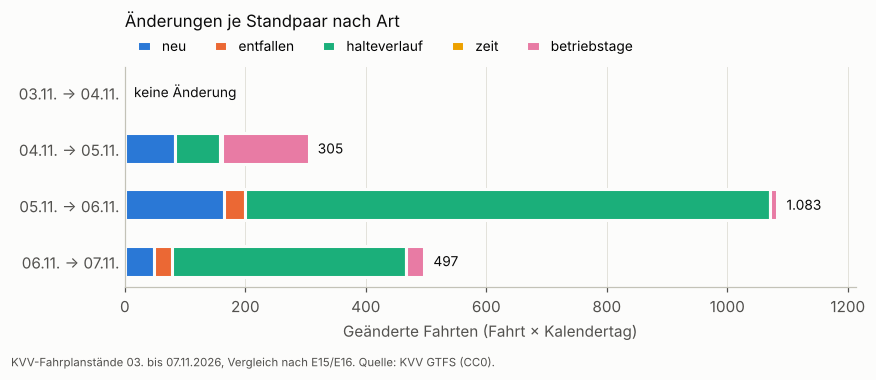

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.4))
y = range(len(tab))[::-1]                 # ältestes Paar oben
links = pd.Series(0, index=tab.index)
for art in ARTEN:
    ax.barh(list(y), tab[art], left=links, height=0.55, color=FARBE[art], label=art,
            edgecolor=FLAECHE, linewidth=2)
    links += tab[art]
for yi, (paar, summe) in zip(y, tab["gesamt"].items()):
    ax.annotate("keine Änderung" if summe == 0 else f"{summe:,}".replace(",", "."), (summe, yi),
                xytext=(6, 0), textcoords="offset points", va="center", color=TEXT, fontsize=9)
ax.set_yticks(list(y), tab.index)
ax.tick_params(axis="y", length=0)
ax.grid(axis="y", visible=False)
ax.set_xlim(0, tab["gesamt"].max() * 1.12)
ax.set_xlabel("Geänderte Fahrten (Fahrt × Kalendertag)")
ax.legend(frameon=False, ncol=5, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=9, handlelength=1)
ax.set_title("Änderungen je Standpaar nach Art", loc="left", color=TEXT, fontsize=11, pad=26)
fig.text(0.01, 0.005, "KVV-Fahrplanstände 03. bis 07.11.2026, Vergleich nach E15/E16. Quelle: KVV GTFS (CC0).",
         color=TEXT2, fontsize=7.5)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(GRAFIKEN / "aenderungen_je_standpaar.png")

Am 06.11. ist es fast nur der Halteverlauf: Linie 164 bedient ab 16.11. zusätzlich die neue Station Ruit Lerchenweg, die schon in Phase 3 als einzige neue Station aufgefallen war. Am 07.11. ist eine angekündigte Umleitung der Linien 44 und 47 ab 30.11. wieder zurückgenommen.

## Warum nicht einfach über trip_id?

E15 begründet, warum ich Fahrten über einen eigenen Schlüssel aus Linie, Richtung, erster Station und erster Abfahrt verbinde. Zum Vergleich steht in `dim_standpaar`, was ein Abgleich der trip_ids im selben Fenster melden würde. Die Spalten zählen verschiedene trip_ids, nicht Fahrt-Instanzen, die Zahlen sind deshalb nur grob vergleichbar. Eine Grafik wäre hier irreführend, eine Tabelle reicht.

In [5]:
paare[["paar", "trip_id_nur_alt", "trip_id_nur_neu", "geaendert"]].assign(
    neu=tab["neu"].values, entfallen=tab["entfallen"].values)

,paar,trip_id_nur_alt,trip_id_nur_neu,geaendert,neu,entfallen
0,03.11. → 04.11.,0,0,0,0,0
1,04.11. → 05.11.,73,2742,173,83,1
2,05.11. → 06.11.,70,186,918,165,35
3,06.11. → 07.11.,319,48,419,48,30


Der trip_id-Abgleich liegt in beide Richtungen daneben. Am 05.11. bekommen 2.742 Fahrten eine neue trip_id, ganz überwiegend bei gleichem Inhalt, also neu nummeriert. Er würde Tausende Änderungen melden, wo es 305 gibt. Am 07.11. ist es umgekehrt: Die Umleitung von 44 und 47 wird zurückgenommen, indem die schon vorhandenen normalen Fahrten wieder an diesen Tagen verkehren. Deren trip_ids gab es auch vorher, ein Abgleich über trip_id sieht bei ihnen nichts.

## Kurzfristigkeit

Wie viele Tage vor der Fahrt stand die Änderung zum ersten Mal im Feed? Gemessen vom Abruf des neuen Stands bis zum Kalendertag der Fahrt.

In [6]:
STUFEN = ["1 am selben Tag", "2 am Vortag", "3 bis 7 Tage", "4 bis 14 Tage", "5 bis 4 Wochen", "6 mehr als 4 Wochen"]
kurz = (sql("SELECT vorlauf_stufe, sum(fahrten)::int AS fahrten FROM v_kurzfristigkeit GROUP BY 1")
        .set_index("vorlauf_stufe")["fahrten"].reindex(STUFEN, fill_value=0))
kurz.index = ["am selben Tag", "am Vortag", "2 bis 7 Tage", "8 bis 14 Tage", "15 bis 28 Tage", "mehr als 28 Tage"]
kurz.to_frame()

,fahrten
am selben Tag,0
am Vortag,0
2 bis 7 Tage,37
8 bis 14 Tage,576
15 bis 28 Tage,792
mehr als 28 Tage,480


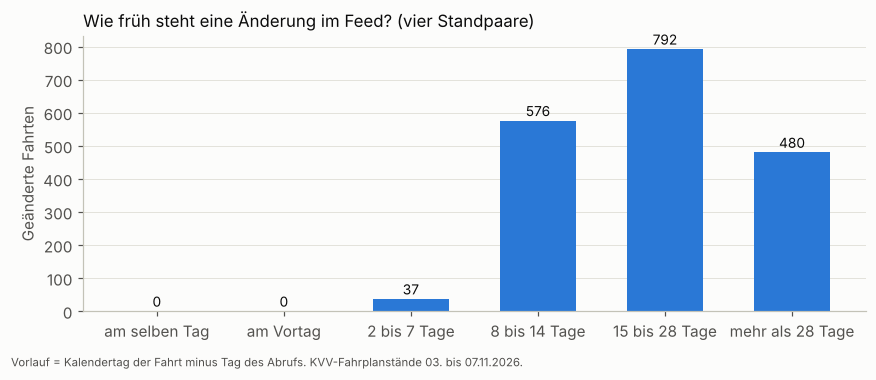

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.bar(kurz.index, kurz.values, width=0.6, color=FARBE["neu"])
for x, wert in enumerate(kurz.values):
    ax.annotate(f"{wert:,}".replace(",", "."), (x, wert), xytext=(0, 3), textcoords="offset points",
                ha="center", color=TEXT, fontsize=9)
ax.grid(axis="x", visible=False)
ax.set_ylabel("Geänderte Fahrten")
ax.set_title("Wie früh steht eine Änderung im Feed? (vier Standpaare)", loc="left", color=TEXT, fontsize=11)
fig.text(0.01, 0.005, "Vorlauf = Kalendertag der Fahrt minus Tag des Abrufs. KVV-Fahrplanstände 03. bis 07.11.2026.",
         color=TEXT2, fontsize=7.5)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(GRAFIKEN / "kurzfristigkeit.png")

Bisher keine einzige Änderung für den selben Tag oder den Vortag, die meisten liegen zwei bis vier Wochen voraus. Das passt zu einem Verbund, der Baustellen und Umleitungen mit Vorlauf einplant. Kurzfristiges, zum Beispiel ein Ausfall wegen Personalmangel, würde ohnehin eher in Echtzeitdaten auftauchen als im Soll-Fahrplan. Mit einem täglichen Abruf ist die Messung auf einen Tag genau. Wenn ein Abruf fehlschlägt, markiert `v_kurzfristigkeit` das Paar als `ungenau`.

## Linien und Haltestellen

In [8]:
sql("""SELECT kurzname AS linie, verkehrsmittel, standpaare, standpaare_mit_aenderung, quote_mit_grossen AS stabilitaet
         FROM v_stabilitaet_linie_gesamt ORDER BY quote_mit_grossen, kurzname LIMIT 10""")

,linie,verkehrsmittel,standpaare,standpaare_mit_aenderung,stabilitaet
0,164,Bus,4,1,0.8163
1,44,Bus,4,1,0.9483
2,47,Bus,4,1,0.9863
3,E,Zug,4,1,0.9922
4,S41,Zug,4,1,0.9933
5,S42,Zug,4,1,0.9975
6,S8,Zug,4,1,0.9979
7,S31,Zug,4,1,0.9988
8,S7,Zug,4,1,0.9990
9,S4,Zug,4,1,0.9995


In [9]:
sql("""SELECT name, gemeinde, standpaare_mit_aenderung, standpaare_gesamt
         FROM v_aenderung_haltestelle ORDER BY standpaare_mit_aenderung DESC, name LIMIT 10""")

,name,gemeinde,standpaare_mit_aenderung,standpaare_gesamt
0,KA Hauptbahnhof (Vorplatz),Karlsruhe,3,4
1,Bad Friedrichshall Hbf,Bad Friedrichshall,2,4
2,Bad Rappenau,Bad Rappenau,2,4
3,Bad Wimpfen,Bad Wimpfen,2,4
4,Bad Wimpfen-Hohenstadt,Bad Wimpfen,2,4
5,Baden-Baden Bahnhof,Baden-Baden,2,4
6,Bretten Bahnhof,Bretten,2,4
7,Bretten Schulzentrum,Bretten,2,4
8,Bühl ZOB/Bahnhof,Bühl,2,4
9,Gundelsheim (Neckar),Gundelsheim,2,4


Mit vier Paaren ist die Linienliste vor allem eine Liste der Baustellen dieser Woche. Eine Stabilitätsquote von 0,82 bei Linie 164 heißt nicht, dass die Linie unzuverlässig ist, sondern dass sie eine neue Station bekommt. Ob eine Linie dauerhaft oft geändert wird, zeigt sich erst über Wochen.

## Umpacken gegen Ändern

In [10]:
sql("SELECT * FROM v_umpacken_anteil")

,ergebnis,abrufe,prozent
0,Inhalt geändert,4,44.4
1,unverändert,5,55.6


Bisher hat der KVV den Feed nie neu gepackt, ohne dass sich der Inhalt ändert. Jede neue ZIP hatte auch neuen Inhalt. Die Kennzahl bleibt trotzdem drin, weil sie ein Phase-1-Befund war, dass der Hash über den Inhalt und nicht über die ZIP laufen muss.

In [11]:
conn.close()